In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import mglearn
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

In [5]:
from sklearn.utils import Bunch

def load_boston():
    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    target = raw_df.values[1::2, 2]
    feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD',
        'TAX', 'PTRATIO', 'B', 'LSTAT']
    return Bunch(data=data, target=target, feature_names=np.array(feature_names))

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
C:\Users\seita\AppData\Local\Temp\ipykernel_21636\3389948619.py:5: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


In [18]:
from sklearn.preprocessing import PolynomialFeatures

boston = load_boston()
x_train, x_test, y_train, y_test = train_test_split(boston.data, boston.target, random_state=0)

pipe = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(),
    Ridge()
)

In [7]:
# 多項式の次数を決める
param_grid = {
    'polynomialfeatures__degree': [1, 2, 3],
    'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]
}

In [19]:
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5, n_jobs=-1)
grid.fit(x_train, y_train)
print("")


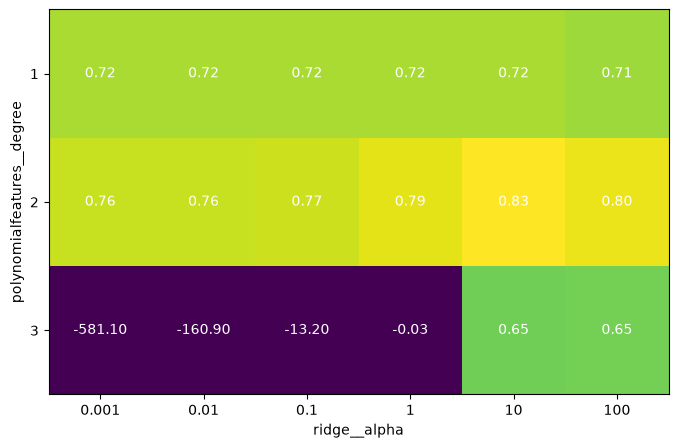

In [ ]:
#交差検証の結果をヒートマップで可視化 

results = pd.DataFrame(grid.cv_results_)

# 交差検証の平均スコア
scores = grid.cv_results_["mean_test_score"].reshape(3, 6)

fig, ax = plt.subplots(figsize=(8, 5))

# ヒートマップ
im = ax.imshow(scores, cmap="viridis", vmin=0, aspect="auto")

# 軸ラベル
ax.set_xlabel("ridge__alpha")
ax.set_ylabel("polynomialfeatures__degree")

# 目盛り
ax.set_xticks(range(6))
ax.set_yticks(range(3))

ax.set_xticklabels(param_grid["ridge__alpha"])
ax.set_yticklabels(param_grid["polynomialfeatures__degree"])

# 各マスにスコアを表示
for i in range(3):
    for j in range(6):
        ax.text(
            j, i, f"{scores[i, j]:.2f}",
            ha="center", va="center",
            color="white"
        )

plt.show()

In [17]:
print("Best parameters: {}".format(grid.best_params_))

Best parameters: {'polynomialfeatures__degree': 2, 'ridge__alpha': 10}


In [20]:
print("Test set score: {:.2f}".format(grid.score(x_test,y_test)))

Test set score: 0.77


In [23]:
#比較のために多項式特徴量を使わずにグリッドリサーチを行ってみる
param_grid = {
    "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

pipe = make_pipeline(
    StandardScaler(),
    Ridge()
)

grid = GridSearchCV(pipe, 
                    param_grid=param_grid,
                    cv=5, 
                    n_jobs=-1
)


grid.fit(x_train, y_train)

print("Score without polynomial features:{:.2f}".format(grid.score(x_test,y_test)))

Score without polynomial features:0.63
